```{index} single: application; cryptocurrency arbitrage
```
```{index} single: solver; HiGHS
```
```{index} web scraping
```
```{index} pandas dataframe
```
```{index} networkx
```
```{index} network optimization
```

# 4.5 Cryptocurrency arbitrage search

## Installations and Imports

## Preamble: Install Pyomo and a solver

The following cell sets and verifies a global SOLVER for the notebook. If run on Google Colab, the cell installs Pyomo and the HiGHS solver, while, if run elsewhere, it assumes Pyomo and HiGHS have been previously installed. It then sets to use HiGHS as solver via the appsi module and a test is performed to verify that it is available. The solver interface is stored in a global object `SOLVER` for later use.

In [2]:
import sys
 
if 'google.colab' in sys.modules:
    %pip install pyomo >/dev/null 2>/dev/null
    %pip install highspy >/dev/null 2>/dev/null
 
solver = 'appsi_highs'
 
import pyomo.environ as pyo
SOLVER = pyo.SolverFactory(solver)

assert SOLVER.available(), f"Solver {solver} is not available."

## Problem description

Cryptocurrency exchanges are web services that enable the purchase, sale, and exchange of cryptocurrencies. These exchanges provide liquidity for owners and establish the relative value of these currencies. Joining an exchange enables a user to maintain multiple currencies in a digital wallet, buy and sell currencies, and use cryptocurrencies for financial transactions.

In this notebook, we explore the efficiency of cryptocurrency exchanges by testing for arbitrage opportunities. An arbitrage exists if a customer can realize a net profit through a sequence of risk-free trades. The efficient market hypothesis assumes arbitrage opportunities are quickly identified and exploited by investors. As a result of their trading, prices reach a new equilibrium so that any arbitrage opportunities would be small and fleeting in an efficient market. The question here is whether it is possible, with real-time data and rapid execution, for a trader to profit from these fleeting arbitrage opportunities.

### Additional libraries needed: NetworkX and CCXT

This notebook uses two additional libraries: NetworkX and CCXT. 

[NetworkX](https://networkx.org/) is a Python library for the creation, manipulation, and study of the structure, dynamics, and functions of complex networks, which is installed by default on Google Colab. 

[CCXT](https://github.com/ccxt/ccxt) is an open-source library for connecting to cryptocurrency exchanges. The CCXT library is not installed by default in Google Colab, so it must be installed with the following command.

    %pip install ccxt


In [3]:
if 'google.colab' in sys.modules:
    %pip install -q ccxt

We import all the libraries we need for this notebook in the following cell.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import ccxt
import glob

### Available cryptocurrency exchanges

Here we use the `ccxt` library and list current exchanges supported by `ccxt`.

In [5]:
print("Available exchanges:\n")
for i, exchange in enumerate(ccxt.exchanges):
    print(f"{i+1:3d}) {exchange.ljust(20)}", end="" if (i + 1) % 4 else "\n")

Available exchanges:

  1) alpaca                2) apex                  3) aster                 4) backpack            
  5) bequant               6) bigone                7) binance               8) binancecoinm        
  9) binanceus            10) binanceusdm          11) bingx                12) bit2c               
 13) bitbank              14) bitbns               15) bitfinex             16) bitflyer            
 17) bitget               18) bithumb              19) bitmex               20) bitopro             
 21) bitrue               22) bitso                23) bitstamp             24) bitteam             
 25) bittrade             26) bitvavo              27) blockchaincom        28) blofin              
 29) btcbox               30) btcmarkets           31) btcturk              32) btse                
 33) bullish              34) bybit                35) bybiteu              36) bydfi               
 37) cex                  38) coinbase             39) coinbaseexchan

## Representing an exchange as a directed graph

First, we need some terminology. Trading between two specific currencies is called a market, with each exchange hosting multiple markets. `ccxt` labels each market with a symbol common across exchanges. The market symbol is an upper-case string with abbreviations for a pair of traded currencies separated by a slash ($/$). The first abbreviation is the base currency, the second is the quote currency. Prices for the base currency are denominated in units of the quote currency. As an example, $ETH/BTC$ refers to a market for the base currency Ethereum (ETH) quoted in units of the Bitcoin (BTC). The same market symbol can refer to an offer to buy the base currency (a 'bid') or to an offer to sell the base currency (an 'ask'). For example, $x$ ETH/BTC means you can buy $x$ units of BTC with one unit of ETH.

An exchange can be represented by a directed graph constructed from the market symbols available on that exchange. In such a graph currencies correspond to nodes on the directed graph. Market symbols correspond to edges in the directed graph, with the source indicating the quote currency and the destination indicating the base currency. The following code develops such a sample graph from a recorded list of the exchange's markets. It removes every terminal base currency whose in-degree is below `minimum_in_degree`; currencies that also serve as quotes are retained. This is a graph of available markets, not the saved order-book snapshot used in the next section. Its size can change as markets are added or removed.

The default uses 629 recorded public market symbols from 26 October 2026, so the market graph is reproducible. Set `RUN_LIVE = True` to retrieve current markets and enable the optional downloads at the end. Market-graph arrows point from quote to base and are labelled with the actual base/quote symbol. In the order-book graph below, arrows instead indicate a possible currency conversion and are labelled source → destination.

For the recorded list, a threshold of 10 removes every base-only currency and leaves nine quote currencies with 28 market edges. A surviving base-only currency would need at least ten quote neighbours, so it could not fit in a nine-node graph. For this figure we use a threshold of 7, retaining 11 currencies and 42 edges, including the two light-blue base-only currencies ADA and SOL. Gold marks currencies used as quotes in the full market list, even if their outgoing edges disappear during filtering. The later order-book downloads use their own thresholds.

Using the recorded public market list from 26 October 2026.
Binance US - Minimum indegree (terminal base currencies) = 7
Number of nodes =  11
Number of edges =  42


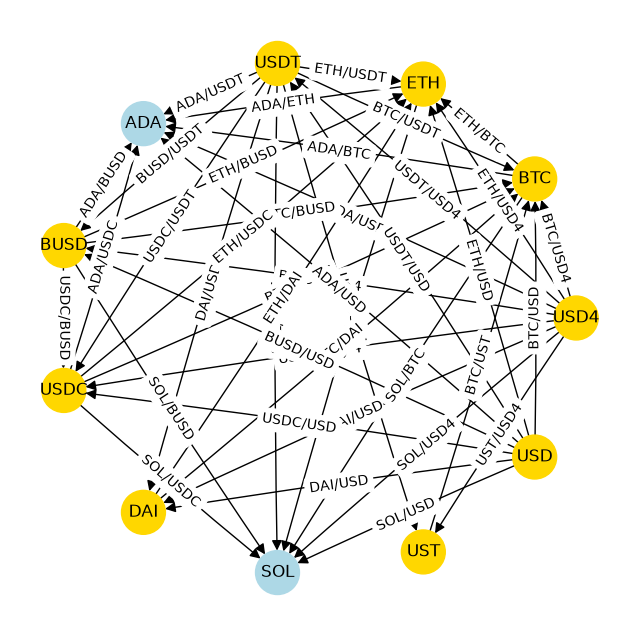

In [6]:
# Live exploration is optional; the default uses recorded public market symbols.
RUN_LIVE = False

# create an exchange object
exchange = ccxt.binanceus({"enableRateLimit": True, "timeout": 10000})


def get_exchange_dg(exchange, minimum_in_degree=1, symbols=None):
    if symbols is None:
        symbols = exchange.load_markets().keys()

    # create an edge for all market symbols
    dg = nx.DiGraph()
    for base, quote in [symbol.split("/") for symbol in symbols]:
        dg.add_edge(quote, base, color="k", width=1, symbol=f"{base}/{quote}")

    # Preserve currency roles from the full market list before filtering.
    quote_currencies = {node for node in dg if dg.out_degree(node) > 0}

    # remove base currencies with in_degree less than minimum_in_degree
    remove_nodes = [
        node
        for node in dg.nodes
        if dg.out_degree(node) == 0 and dg.in_degree(node) < minimum_in_degree
    ]
    dg.remove_nodes_from(remove_nodes)

    # color quote currencies in gold
    for node in dg.nodes():
        dg.nodes[node]["color"] = "gold" if node in quote_currencies else "lightblue"

    return dg


def draw_dg(dg, rad=0.0):
    n_nodes = len(dg.nodes)
    size = int(2.5 * np.sqrt(n_nodes))
    fig = plt.figure(figsize=(size, size))
    pos = nx.circular_layout(dg)
    nx.draw_networkx(
        dg,
        pos,
        with_labels=True,
        node_color=[dg.nodes[node]["color"] for node in dg.nodes()],
        edge_color=[dg.edges[u, v]["color"] for u, v in dg.edges],
        width=[dg.edges[u, v]["width"] for u, v in dg.edges],
        node_size=1000,
        font_size=12,
        arrowsize=15,
        connectionstyle=f"arc3, rad={rad}",
    )
    nx.draw_networkx_edge_labels(
        dg, pos, edge_labels={(src, dst): dg[src][dst].get("symbol", f"{src} → {dst}") for src, dst in dg.edges()}
    )
    plt.axis("off")

    return plt.gca()


import json
from pathlib import Path
from urllib.request import urlopen

market_file = "Binance_US_market_symbols_20261026.json"
if "google.colab" in sys.modules:
    url = "https://raw.githubusercontent.com/mobook/MO-book/main/notebooks/04/data/" + market_file
    with urlopen(url) as response:
        recorded_symbols = json.load(response)
else:
    recorded_symbols = json.loads(Path("data", market_file).read_text())

# This display threshold is separate from the later order-book downloads.
minimum_in_degree = 7
symbols = recorded_symbols
if RUN_LIVE:
    try:
        symbols = list(exchange.load_markets())
        print("Market list retrieved at", pd.Timestamp.now(tz="UTC").isoformat())
    except ccxt.BaseError as error:
        print(f"Live market list unavailable; using the recorded list: {error}")
else:
    print("Using the recorded public market list from 26 October 2026.")
exchange_dg = get_exchange_dg(exchange, minimum_in_degree, symbols=symbols)
ax = draw_dg(exchange_dg, 0.01)
print(exchange.name + f" - Minimum indegree (terminal base currencies) = {minimum_in_degree}")
print(f"Number of nodes = {len(exchange_dg.nodes()):3d}")
print(f"Number of edges = {len(exchange_dg.edges()):3d}")


## Exchange order book

The order book for a currency exchange is the real-time inventory of trading orders. 

A **bid** is an offer to buy up to a specified amount of the base currency at the price not exceeding the 'bid price' in the quote currency.  An **ask** is an offer to sell up to a specified amount of the base currency at a price no less than a value specified given in the quote currency. 

The exchange attempts to match the bid to ask order at a price less than or equal to the bid price. If a transaction occurs, the buyer will receive an amount of base currency less than or equal to the bid volume and the ask volume, at a price less than or equal to the bid price and no less than the specified value.

The order book for currency exchange is the real-time inventory of orders. The exchange order book maintains a list of all active orders for symbols traded on the exchange. Incoming bids above the lowest ask or incoming asks below the highest bid will be immediately matched and transactions executed following the rules of the exchange.

The following cell reads and displays a previously saved order book. Cells at the end of this notebook demonstrate how to retrieve an order book from an exchange and save it as a Pandas DataFrame.

In [7]:
filename = "Binance_US_orderbook_saved.csv"
if "google.colab" in sys.modules:
    order_book = pd.read_csv(
        "https://raw.githubusercontent.com/mobook/MO-book/main/notebooks/04/data/"
        + filename,
        index_col=0,
    )
else:
    order_book = pd.read_csv("data/" + filename, index_col=0)

display(order_book)

,symbol,timestamp,base,quote,bid_price,bid_volume,ask_price,ask_volume
0,ETH/BTC,2023-03-02 15:36:06.529,ETH,BTC,0.069735,0.012000,0.069759,0.050000
1,BNB/BTC,2023-03-02 15:36:06.583,BNB,BTC,0.012743,0.050000,0.012755,3.000000
2,ADA/BTC,2023-03-02 15:36:06.637,ADA,BTC,0.000015,2.000000,0.000015,2168.000000
3,SOL/BTC,2023-03-02 15:36:06.690,SOL,BTC,0.000935,1.420000,0.000936,15.120000
4,MATIC/BTC,2023-03-02 15:36:06.750,MATIC,BTC,0.000052,26.200000,0.000052,150.200000
5,MANA/BTC,2023-03-02 15:36:06.848,MANA,BTC,0.000027,831.000000,0.000027,1409.000000
6,TRX/BTC,2023-03-02 15:36:06.905,TRX,BTC,0.000003,4.000000,0.000003,25352.000000
7,ADA/ETH,2023-03-02 15:36:06.960,ADA,ETH,0.000214,994.900000,0.000214,891.600000
8,BTC/USDT,2023-03-02 15:36:07.012,BTC,USDT,23373.920000,0.118619,23376.000000,0.045275
9,ETH/USDT,2023-03-02 15:36:07.065,ETH,USDT,1630.200000,0.950000,1630.770000,0.500000


## Modelling the arbitrage search problem as a graph

Our goal will be to find arbitrage opportunities, i.e., the possibility to start from a given currency and, through a sequence of executed trades, arrive back at the same currency with a higher balance than at the beginning. We will model this problem as a network one.

A bid appearing in the order book for the market symbol $b/q$ is an order from a prospective counter party to purchase an amount of the base currency $b$ at a bid price given in a quote currency $q$. For a currency trader, a bid in the order book is an opportunity to convert the base currency $b$ into the quote currency $q$.

The order book can be represented as a directed graph where the nodes correspond to individual currencies. A directed edge $b\rightarrow q$ from node $b$ to node $q$ describes an opportunity for us to convert currency $b$ into units of currency $q$. Let $V_b$ and $V_q$ denote the amounts of each currency held by us, and let $x_{b\rightarrow q}$ denote the amount of currency $b$ exchanged for currency $q$. Following the transaction $x_{b\rightarrow q}$ we have the following changes to the currency holdings

$$
\begin{align*}
    \Delta V_b & = - x_{b\rightarrow q} \\
    \Delta V_q & = a_{b\rightarrow q} x_{b\rightarrow q},
\end{align*}
$$

where $a_{b\rightarrow q}$ is a *conversion coefficient* equal to the price of $b$ expressed in terms of currency $q$. The capacity $c_{b\rightarrow q}$ of a trading along edge $b\rightarrow q$ is specified by a relationship

$$
    x_{b\rightarrow q} \leq c_{b\rightarrow q}.
$$

Because the arcs in our graph correspond to two types of orders - bid and ask - we need to build a consistent way of expressing them in our  $a_{b\rightarrow q}$, $c_{b\rightarrow q}$ notation. Imagine now that we are the party that accepts the bid and ask orders existing in the graph.

For bid orders, we have the opportunity to convert the base currency $b$ into the quote currency $q$, for which we will use the following notation:

$$
\begin{align*}
a_{b\rightarrow q} & = \text{bid price} \\
c_{b\rightarrow q} & = \text{bid volume}
\end{align*}
$$

An ask order for symbol $b/q$ is an order to sell the base currency at a price not less than the 'ask' price given in terms of the quote currency. The ask volume is the amount of base currency to be sold. For us, a sell order is an opportunity to convert the quoted currency into the base currency such that

$$
\begin{align*}
a_{q\rightarrow b} & = \frac{1}{\text{ask price}} \\
c_{q\rightarrow b} & = \text{ask volume} \times \text{ask price}
\end{align*}
$$

The following cell creates a directed graph using data from an exchange order book. To distinguish between different order types, we will highlight the bid orders with green color, and ask orders with red color.

In [8]:
def order_book_to_dg(order_book):
    # create a dictionary of edges indexed by (src, dst)
    dg_order_book = nx.DiGraph()

    # loop over each order in the order book dataframe
    for order in order_book.index:
        # if the order is a 'bid', i.e., an order to purchase the base currency
        if not np.isnan(order_book.at[order, "bid_volume"]):
            src = order_book.at[order, "base"]
            dst = order_book.at[order, "quote"]
            # add an edge to the graph with the relevant attributes
            dg_order_book.add_edge(
                src,
                dst,
                kind="bid",
                a=order_book.at[order, "bid_price"],
                capacity=order_book.at[order, "bid_volume"],
                weight=-np.log(order_book.at[order, "bid_price"]),
                color="g",
                width=0.5,
            )

        # if the order is an 'ask', i.e., an order to sell the base currency
        if not np.isnan(order_book.at[order, "ask_volume"]):
            src = order_book.at[order, "quote"]
            dst = order_book.at[order, "base"]
            # add an edge to the graph with the relevant attributes
            dg_order_book.add_edge(
                src,
                dst,
                kind="ask",
                a=1.0 / order_book.at[order, "ask_price"],
                capacity=order_book.at[order, "ask_volume"]
                * order_book.at[order, "ask_price"],
                weight=-np.log(1.0 / order_book.at[order, "ask_price"]),
                color="r",
                width=0.5,
            )

    # loop over each node in the graph and set the color attribute to "lightblue"
    for node in dg_order_book.nodes():
        dg_order_book.nodes[node]["color"] = "lightblue"

    return dg_order_book


order_book_dg = order_book_to_dg(order_book)

First, we simply print the content of the order book as a list of arcs.

In [9]:
# display contents of the directed graph
print(f"src   --> dst    kind            a                c")
print(f"------------------------------------------------------")
for src, dst in order_book_dg.edges():
    print(
        f"{src:5s} --> {dst:5s}   {order_book_dg.edges[(src, dst)]['kind']}"
        + f"{order_book_dg.edges[(src, dst)]['a']: 16f} {order_book_dg.edges[(src, dst)]['capacity']: 16f}    "
    )

src   --> dst    kind            a                c
------------------------------------------------------
ETH   --> BTC     bid        0.069735         0.012000    
ETH   --> ADA     ask     4668.534080         0.190981    
ETH   --> USDT    bid     1630.200000         0.950000    
ETH   --> BUSD    bid     1630.210000         0.510000    
ETH   --> USDC    bid     1630.160000         0.100000    
ETH   --> DAI     bid     1629.890000         0.497400    
ETH   --> USD     bid     1630.490000         2.564550    
BTC   --> ETH     ask       14.335068         0.003488    
BTC   --> BNB     ask       78.403701         0.038263    
BTC   --> ADA     ask    66844.919786         0.032433    
BTC   --> SOL     ask     1068.261938         0.014154    
BTC   --> MATIC   ask    19391.118868         0.007746    
BTC   --> MANA    ask    36968.576710         0.038113    
BTC   --> TRX     ask   335570.469799         0.075549    
BTC   --> USDT    bid    23373.920000         0.118619    
BTC   --

Next, we draw the graph itself.

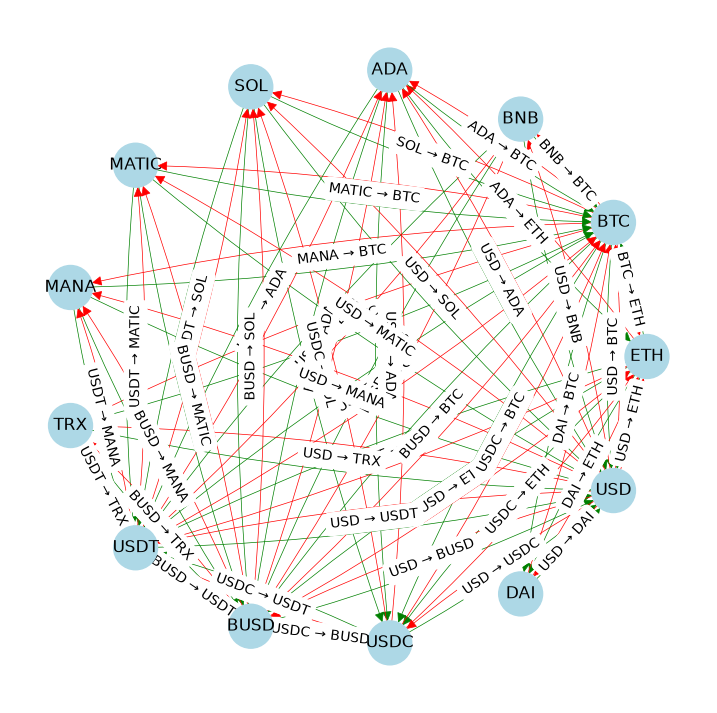

In [10]:
draw_dg(order_book_dg, 0.05)
plt.show()

## Trading and arbitrage

With this unified treatment of bid and ask orders, we are ready to formulate the mathematical problem of finding an arbitrage opportunity. An arbitrage exists if it is possible to find a closed path and a sequence of transactions in the directed graph resulting in a net increase in currency holdings. Given a path

$$
\begin{align*}
    i_0 \rightarrow i_1 \rightarrow i_2 \rightarrow \cdots \rightarrow i_{n-1} \rightarrow i_n
\end{align*}
$$

the path is closed if $i_n = i_0$. A positive volume can traverse the path if every edge has positive capacity. For a sufficiently small holding $w_{i_0}$ of currency $i_0$ (because of capacity constraints), a closed path with $i_0 = i_n$ represents an arbitrage opportunity if 

$$
\begin{equation} 
    \prod_{k=0}^{n-1} a_{i_k\rightarrow i_{k+1}} > 1.
\end{equation}
$$

If all we care about is simply finding an arbitrage cycle, regardless of the volume traded, we can use one of the many shortest path algorithms from the `networkx` library. To convert the problem of finding a path meeting  the above condition into a sum-of-terms to be minimized, we can take the negative logarithm of both sides to obtain the condition:

$$
\begin{align*}
    -\log(\prod_{k=0}^{n-1} a_{i_k\rightarrow i_{k+1}}) = - \sum\limits_{k = 0}^{n-1} \log (a_{i_k\rightarrow i_{k+1}}) < 0,
\end{align*}
$$

In other words, if we assign the negative logarithm as the weight of arcs in a graph, then our problem just becomes translated into the problem of searching for a cycle with a total sum of weights along it to be negative.

## Find order books that have arbitrage opportunities

A *simple cycle* is a closed path in which no node appears twice. Simple cycles are distinct if they are not cyclic permutations (essentially, the same set of nodes but with a different start and end points) of each other. One could check for arbitrage opportunities by checking if there are any negative simple cycles in the graph.

However, searching for a negative-weight cycle through searching for an arbitrage opportunity can be a daunting task - a brute-force search over all simple cycles has complexity $(n + e)(c + 1)$ which is impractical for large-scale applications. A more efficient search based on the Bellman-Ford algorithm is embedded in the NetworkX function [`negative_edge_cycle`](https://networkx.org/documentation/networkx-1.10/reference/generated/networkx.algorithms.shortest_paths.weighted.negative_edge_cycle.html) that returns a logical True if a negative cycle exists in a directed graph. 

In [11]:
order_book_dg = order_book_to_dg(order_book)
nx.negative_edge_cycle(order_book_dg, weight="weight", heuristic=True)

True

The function `negative_edge_cycle` is fast, but it only indicates if there is a negative cycle or not, and we don't even know what kind of a cycle is it so it would be hard to use that information to perform an arbitrage.

Luckily, the `networkx` library includes the function [`find_negative_cycle`](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.shortest_paths.weighted.find_negative_cycle.html) that locates a single negative edge cycle if one exists. We can use this to demonstrate the existence of an arbitrage opportunity and to highlight that opportunity on the directed graph of all possible trades. The following cell reports the cycle found and the corresponding trading return measured in basis points (1 basis point = 0.01%). The same trading cycle is marked with thicker arcs in the graph.

Trading cycle with 3 trades: USDC --> USDT --> BUSD --> USDC
Return =  5.002 basis points 


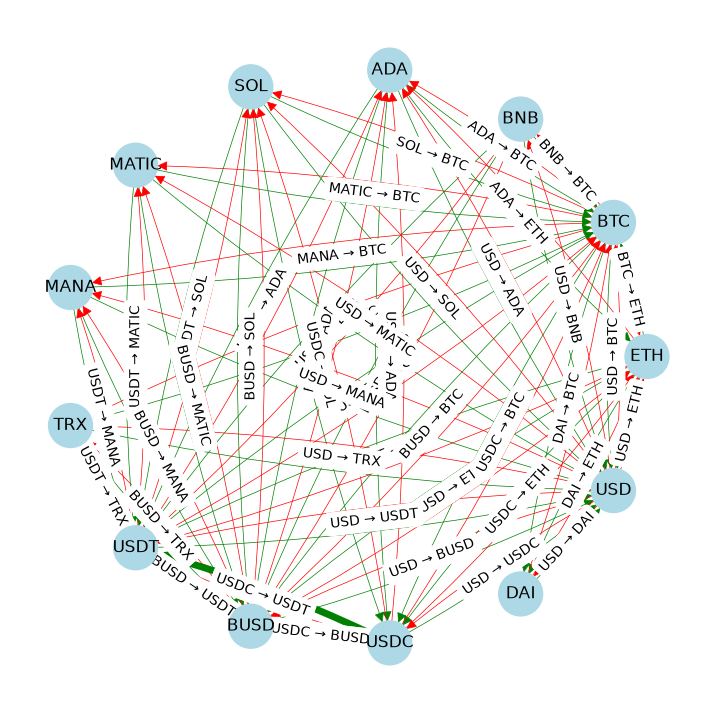

In [12]:
def sum_weights(cycle):
    return sum(
        [
            order_book_dg.edges[edge]["weight"]
            for edge in zip(cycle, cycle[1:] + cycle[:1])
        ]
    )


order_book_dg = order_book_to_dg(order_book)
arb = nx.find_negative_cycle(order_book_dg, weight="weight", source="USD")[:-1]
bp = 10000 * (np.exp(-sum_weights(arb)) - 1)

for src, dst in zip(arb, arb[1:] + arb[:1]):
    order_book_dg[src][dst]["width"] = 5

print(
    f"Trading cycle with {len(list(arb))} trades: {' --> '.join(list(arb) + [arb[0]])}\nReturn = {bp:6.3f} basis points "
)
ax = draw_dg(order_book_dg, 0.05)
plt.show()

Note this may or may not be the trading cycle with maximum return. There may be other cycles with higher or lower returns, and that allow higher or lower trading volumes.

## Brute force search arbitrage with simple cycles

Not all arbitrage cycles are the same - some yield a higher relative return (per dollar invested) than the others, and some yield a higher absolute return (maximum amount of money to be made risk-free) than others. This is because each order limits the volume that can traverse the cycle. The capacities must first be expressed in the starting currency: for the cycle $i_0,\ldots,i_n=i_0$, the starting amount is bounded by $\min_{0\leq k<n} c_{i_k\rightarrow i_{k+1}}/\prod_{h=0}^{k-1}a_{i_h\rightarrow i_{h+1}}$, with the empty product equal to one. Taking the minimum of the raw capacities would compare quantities in different currencies. Thus, if one is looking for the best possible arbitrage sequence of trades, finding just 'a cycle' might not be enough.

A crude way to search for a good arbitrage opportunity would be to enumerate all possible simple cycles in a graph and pick the one that's best according to whatever criterion we pick. A brute force search over for all simple cycles has order $(N_{nodes} + N_{edges})(N_{cycles} + 1)$ complexity, which is prohibitive for large order books. Nevertheless, we explore this option here to better understand the problem of finding and valuing arbitrage opportunities.

In the following cell, we compute the loss function for all simple cycles that can be constructed within a directed graph using the function [`simple_cycles`](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.cycles.simple_cycles.html) from the `networkx` library to construct a dictionary of all distinct simple cycles in the order book. Each cycle is represented by an ordered list of nodes. For each cycle, the financial return is computed, and a histogram is constructed to show the distribution of potential returns. Several paths with the highest return are then overlaid on the graph of the order book.

Again, note that no account is taken of the trading capacity available on each path.

The next cell iterates over all simple cycles in a directed graph. This can take a long time for a large dense graph.

There are 203147 distinct simple cycles in the order book, 974 of which have positive return.


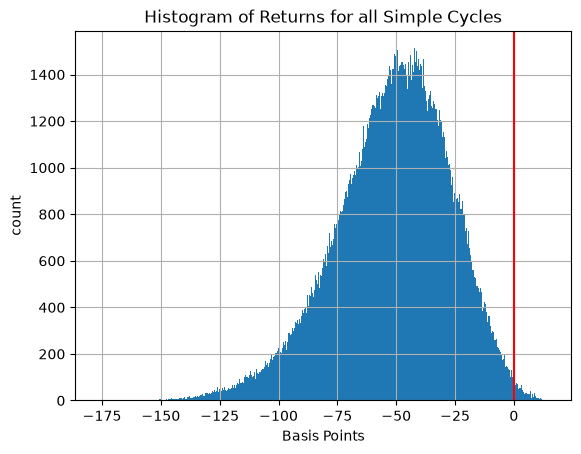

In [13]:
# convert order book to a directed graph
order_book_dg = order_book_to_dg(order_book)


# compute the sum of weights given a list of nodes
def sum_weights(cycle):
    return sum(
        [
            order_book_dg.edges[edge]["weight"]
            for edge in zip(cycle, cycle[1:] + cycle[:1])
        ]
    )


# create a dictionary of all simple cycles and sum of weights
cycles = {
    tuple(cycle): 10000 * (np.exp(-sum_weights(cycle)) - 1)
    for cycle in nx.simple_cycles(order_book_dg)
}

print(
    f"There are {len(cycles)} distinct simple cycles in the order book, {len([cycle for cycle in cycles if cycles[cycle] > 0])} of which have positive return."
)

# create histogram
plt.hist(cycles.values(), bins=int(np.sqrt(len(cycles))))
ax = plt.gca()
ax.set_ylabel("count")
ax.set_xlabel("Basis Points")
ax.set_title("Histogram of Returns for all Simple Cycles")
ax.grid(True)
ax.axvline(0, color="r")
plt.show()

Next, we sort out the negative cycles from this list and present them along with their basis-points (1% is 100 basis points) return.

In [14]:
arbitrage = [
    cycle for cycle in sorted(cycles, key=cycles.get, reverse=True) if cycles[cycle] > 0
]

n_cycles_to_list = 5

print(f"Top {n_cycles_to_list}\n")
print(f"Basis Points             Arbitrage Cycle")
for cycle in arbitrage[0 : min(n_cycles_to_list, len(arbitrage))]:
    t = list(cycle)
    t.append(cycle[0])
    print(f"{cycles[cycle]:6.3f}         {len(cycle)} trades: {' --> '.join(t)}")

Top 5

Basis Points             Arbitrage Cycle
14.774         7 trades: USDC --> USDT --> ADA --> BTC --> ETH --> USD --> BUSD --> USDC
14.747         7 trades: USDC --> USDT --> TRX --> BTC --> ETH --> USD --> BUSD --> USDC
14.699         6 trades: USDC --> USDT --> ADA --> BTC --> USD --> BUSD --> USDC
14.673         6 trades: USDC --> USDT --> TRX --> BTC --> USD --> BUSD --> USDC
13.772         6 trades: USDC --> USDT --> ADA --> BTC --> ETH --> USD --> USDC


In the end, we draw an example arbitrage cycle on our graph to illustrate the route that the money must travel.

Trading cycle with 7 trades: USDC --> USDT --> ADA --> BTC --> ETH --> USD --> BUSD --> USDC
Return = 14.774 basis points 


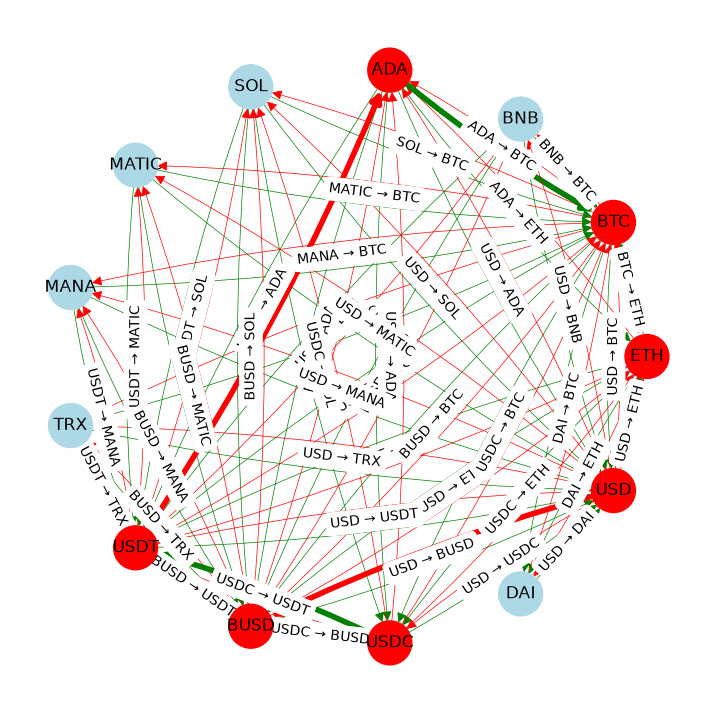

In [15]:
n_cycles_to_show = 1

for cycle in arbitrage[0 : min(n_cycles_to_show, len(arbitrage))]:
    t = list(cycle) + [cycle[0]]
    print(
        f"Trading cycle with {len(cycle)} trades: {' --> '.join(t)}\nReturn = {cycles[cycle]:6.3f} basis points "
    )
    # get fresh graph to color nodes
    order_book_dg = order_book_to_dg(order_book)

    # color nodes red
    for node in cycle:
        order_book_dg.nodes[node]["color"] = "red"

    # makes lines wide
    for edge in zip(cycle, cycle[1:] + cycle[:1]):
        order_book_dg.edges[edge]["width"] = 4

    ax = draw_dg(order_book_dg, rad=0.05)

    plt.show()

## Pyomo model for arbitrage with capacity constraints

The preceding analysis demonstrates some practical limitations of relying on generic implementations of network algorithms:

* First, more than one negative cycle may exist, so more than one arbitrage opportunity may exist, i.e. an optimal strategy consists of a combination of cycles.

* Secondly, simply searching for a negative cycle using shortest path algorithms does not account for capacity constraints, i.e., the maximum size of each of the exchanges. For that reason, one may end up with a cycle on which a good `rate' of arbitrage is available, but where the absolute gain need not be large due to the maximum amounts that can be traded.
    
Instead, we can formulate the problem of searching for a maximum-gain arbitrage via linear optimization. Assume that we are given a directed graph where each edge $i\rightarrow j$ is labeled with a 'multiplier' $a_{i\rightarrow j}$ indicating how many units of currency $j$ will be received for one unit of currency $i$, and a 'capacity' $c_{i\rightarrow j}$ indicating how many units of currency $i$ can be converted to currency $j$.

We break the trading process into rounds indexed by $t = 1, 2, \ldots, T$. Each round can contain several simultaneous trades along graph edges, using only currency held at the start of that round. We denote by $x_{i\rightarrow j}(t)$ the amount of currency traded from node $i$ to $j$ in round $t$. In this way, we start with the amount $v_{USD}(0)$ at round $0$ and aim to maximize the amount $v_{USD}(T)$ at round $T$. Denote by $O_j$ the set of nodes to which outgoing arcs from $j$ lead, and by $I_j$ the set of nodes from which incoming arcs lead.

A single transaction converts $x_{i\rightarrow j}(t)$ units of currency $i$ to currency $j$. Following all transactions in round $t$, the trader will hold $v_j(t)$ units of currency $j$ where

$$v_{j}(t) = v_{j}(t-1) + \sum_{i\in I_j} a_{i\rightarrow j}x_{i\rightarrow j}(t) - \sum_{k\in O_j} x_{j\rightarrow k}(t)$$

For every edge $i\rightarrow j$, the sum of all transactions must satisfy

$$\sum_{t=1}^T x_{i\rightarrow j}(t) \leq c_{i\rightarrow j}$$

The objective of the optimization model is to find a sequence of currency transactions that increase the holdings of a reference currency. The solution is constrained by assuming that the trader cannot short sell any currency. The resulting model is

$$
\begin{align*}
\max \quad & v_{USD}(T) \\
\text{s.t.} \quad & v_{USD}(0) = v_0 \\
& v_j(0) = 0 & \forall j\in N\setminus\{USD\} \\ 
& v_{j}(t) = v_{j}(t-1) + \sum_{i\in I_j} a_{i\rightarrow j}x_{i\rightarrow j}(t) - \sum_{k\in O_j} x_{j\rightarrow k}(t) & \forall j\in N, t=1, 2, \ldots, T \\
& v_j(t-1) \geq \sum_{k\in O_j} x_{j\rightarrow k}(t) & \forall j\in N, t = 1, 2, \ldots, T  \\
& \sum_{t=1}^T x_{j\rightarrow k}(t) \leq c_{j\rightarrow k} & \forall (j, k) \in E \\
& v_{j}(t), x_{i\rightarrow j}(t) \geq 0 & \forall t
\end{align*}
$$

where the constraints model:
* the initial USD holdings and zero initial holdings of every other currency,
* the balance equations linking the state of the given node in the previous and subsequent rounds,
* the fact that we cannot trade in round $t$ more of a given currency than we had in this currency from round $t - 1$. This constraint 'enforces' the order of trading rounds, i.e., we cannot trade in round $t$ units which have been received in the same round.
* the maximum allowed trade volumes,
* the non-negativity of the variables.

The following cell implements this optimization model using Pyomo.

In [16]:
def crypto_model(order_book_dg, T=10, v0=100.0):
    if "USD" not in order_book_dg or v0 <= 0 or T < 1:
        raise ValueError("Use a graph containing USD, positive initial wealth and at least one trading step.")
    m = pyo.ConcreteModel("Cryptocurrency arbitrage")

    # length of the trading chain
    m.T0 = pyo.RangeSet(0, T)
    m.T1 = pyo.RangeSet(1, T)

    # currency nodes and trading edges
    m.NODES = pyo.Set(initialize=list(order_book_dg.nodes))
    m.EDGES = pyo.Set(initialize=list(order_book_dg.edges))

    # currency on hand at each node
    m.v = pyo.Var(m.NODES, m.T0, domain=pyo.NonNegativeReals)

    # amount traded on each edge at each trade
    m.x = pyo.Var(m.EDGES, m.T1, domain=pyo.NonNegativeReals)

    # total amount traded on each edge over all trades
    m.z = pyo.Var(m.EDGES, domain=pyo.NonNegativeReals)

    # "multiplier" on each trading edge
    @m.Param(m.EDGES)
    def a(m, src, dst):
        return order_book_dg.edges[(src, dst)]["a"]

    @m.Param(m.EDGES)
    def c(m, src, dst):
        return order_book_dg.edges[(src, dst)]["capacity"]

    @m.Objective(sense=pyo.maximize)
    def wealth(m):
        return m.v["USD", T]

    @m.Constraint(m.EDGES)
    def total_traded(m, src, dst):
        return m.z[src, dst] == sum([m.x[src, dst, t] for t in m.T1])

    @m.Constraint(m.EDGES)
    def edge_capacity(m, src, dst):
        return m.z[src, dst] <= m.c[src, dst]

    # initial assignment of v0 units on a selected currency
    @m.Constraint(m.NODES)
    def initial(m, node):
        if node == "USD":
            return m.v[node, 0] == v0
        return m.v[node, 0] == 0

    @m.Constraint(m.NODES, m.T1)
    def no_shorting(m, node, t):
        out_nodes = [dst for src, dst in m.EDGES if src == node]
        return m.v[node, t - 1] >= sum(m.x[node, dst, t] for dst in out_nodes)

    @m.Constraint(m.NODES, m.T1)
    def balances(m, node, t):
        in_nodes = [src for src, dst in m.EDGES if dst == node]
        out_nodes = [dst for src, dst in m.EDGES if src == node]
        return m.v[node, t] == m.v[node, t - 1] + sum(
            m.a[src, node] * m.x[src, node, t] for src in in_nodes
        ) - sum(m.x[node, dst, t] for dst in out_nodes)

    return m


def solve_crypto_model(order_book_dg, T=10, v0=100.0):
    model = crypto_model(order_book_dg, T=T, v0=v0)
    results = SOLVER.solve(model)
    pyo.assert_optimal_termination(results)
    return model

Using this function, we are able to compute the optimal (absolute) return from an order book while respecting the order capacities and optimally using all the arbitrage opportunities inside it.

In [17]:
order_book_dg = order_book_to_dg(order_book)
v0 = 10000.0
T = 8
m = solve_crypto_model(order_book_dg, T=T, v0=v0)
vT = m.wealth()

print(f"Starting wealth = {v0:0.2f} USD")
print(f"Wealth after {T:2d} trading rounds = {vT:0.2f} USD")
print(f"Return = {10000 * (vT - v0)/v0:0.3f} basis points")

Starting wealth = 10000.00 USD
Wealth after  8 trading rounds = 10009.01 USD
Return = 9.006 basis points


To track the evolution of the trades across rounds, the script in the following cell illustrates, for each currency (rows) the amount of money held in that currency at each of the rounds $t = 0, \dots, 8$. It is visible from this scheme that the sequence of trades is not a simple cycle, but rather a more sophisticated sequence of trades which we would not have discovered with simple-cycle exploration alone, especially not when considering also the arc capacities.

In [18]:
for node in m.NODES:
    print(f"{node:5s}", end="")
    for t in m.T0:
        print(f" {m.v[node, t]():11.5f}", end="")
    print()

ETH      -0.00000    -0.00000    -0.00000    -0.00000    -0.00000    -0.00000     0.00000    -0.00000    -0.00000
BTC      -0.00000    -0.00000    -0.00000    -0.00000     0.00000    -0.00000    -0.00000     0.00004     0.00000
BNB      -0.00000    -0.00000    -0.00000    -0.00000     0.00000    -0.00000    -0.00000    -0.00000    -0.00000
ADA      -0.00000    -0.00000    -0.00000    -0.00000    -0.00000    -0.00000     2.00000    -0.00000     0.00000
SOL      -0.00000    -0.00000    -0.00000    -0.00000     0.00000    -0.00000    -0.00000    -0.00000    -0.00000
MATIC    -0.00000    -0.00000    -0.00000     0.00000    -0.00000     0.00000    -0.00000    -0.00000     0.00000
MANA     -0.00000    -0.00000    -0.00000     0.00000    -0.00000    -0.00000     0.00000    -0.00000    -0.00000
TRX      -0.00000     0.00000    -0.00000    -0.00000     0.00000    -0.00000     4.00000    -0.00000     0.00000
USDT     -0.00000  4953.27897  5046.73033    -0.00000  4955.75660  5049.25470    -0.0000

To be even more specific, the following cell lists the sequence of transactions executed.

In [19]:
print("\nTrading rounds")
for t in m.T1:
    print(f"t = {t}")
    for src, dst in m.EDGES:
        if m.x[src, dst, t]() > 1e-6:
            print(
                f" {src:8s} -> {dst:8s}: {m.x[src, dst, t]():14.6f} {m.a[src, dst] * m.x[src, dst, t]():14.6f}"
            )
    print()


Trading rounds
t = 1
 USD      -> USDT    :    4953.774297    4953.278970
 USD      -> USDC    :    5046.225703    5046.225703

t = 2
 USDT     -> BUSD    :    4953.278970    4955.261074
 USDC     -> USDT    :    5046.225703    5046.730325

t = 3
 USDT     -> BUSD    :    5046.730325    5048.749825
 BUSD     -> USDC    :    4955.261074    4955.261074

t = 4
 BUSD     -> USDC    :    5048.749825    5048.749825
 USDC     -> USDT    :    4955.261074    4955.756600

t = 5
 USDT     -> BUSD    :    4955.756600    4957.739696
 USDC     -> USDT    :    5048.749825    5049.254700

t = 6
 USDT     -> ADA     :       0.697500       2.000000
 USDT     -> BUSD    :    5048.279880    5050.300000
 USDT     -> TRX     :       0.277320       4.000000
 BUSD     -> USDC    :    4957.739696    4957.739696

t = 7
 ADA      -> BTC     :       2.000000       0.000030
 TRX      -> BTC     :       4.000000       0.000012
 BUSD     -> USDC    :    5050.300000    5050.300000
 USDC     -> USDT    :    4957.7396

We next illustrate the arbitrage strategy in the graph by marking all the corresponding arcs thicker.

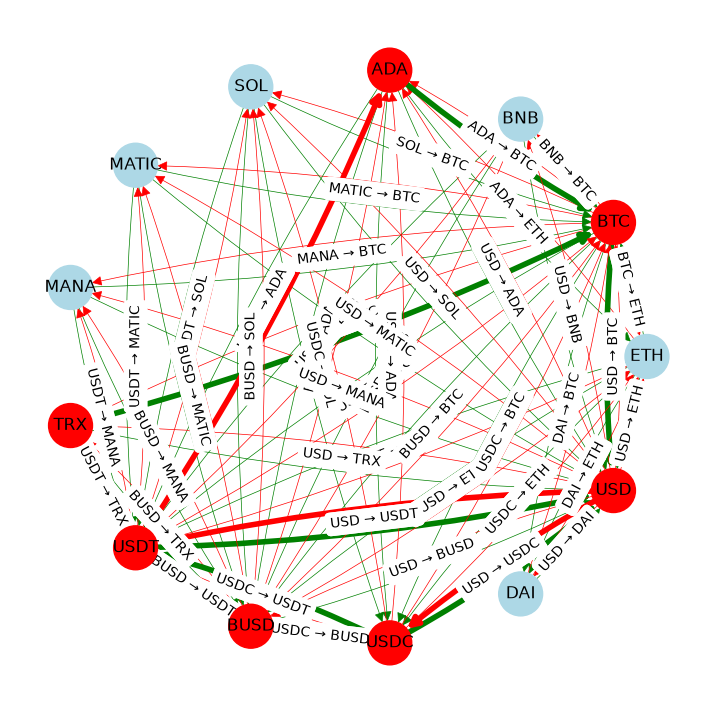

In [20]:
# for each currency we took only one ask and one bid, this is why we are unique between each pair of nodes

# report what orders to issue
for src, dst in m.EDGES:
    if m.z[src, dst]() > 0.0000002:
        order_book_dg.nodes[src]["color"] = "red"
        order_book_dg.nodes[dst]["color"] = "red"
        order_book_dg[src][dst]["width"] = 4

draw_dg(order_book_dg, 0.05)
plt.show()

If we want to be even more precise about the execution of the trading strategy, we can formulate a printout of the list of orders that we, as the counter party to the orders stated in the order book, should issue for our strategy to take place.

In [21]:
# report what orders to issue
print("Trading Summary for the Order Book")
print(f"  Order Book   Type    Capacity         Traded")
for src, dst in m.EDGES:
    if m.z[src, dst]() > 0.0000002:
        kind = order_book_dg.edges[(src, dst)]["kind"]
        s = f"{src:>5s} -> {dst:<5s} {kind} {m.c[src, dst]:12.5f} {m.z[src, dst]():14.5f}"
        s += "  >>>  "
        if kind == "ask":
            base = dst
            quote = src
            symbol = base + "/" + quote
            price = 1.0 / order_book_dg.edges[(src, dst)]["a"]
            volume = m.z[src, dst]() / price
            s += f"buy {volume:15.6f} {symbol:11s} at {price:12.6f}"

        if kind == "bid":
            base = src
            quote = dst
            symbol = base + "/" + quote
            price = order_book_dg.edges[(src, dst)]["a"]
            volume = m.z[src, dst]()
            s += f"sell {volume:16.6f} {symbol:11s} at {price:12.6f}"
        print(s)

Trading Summary for the Order Book
  Order Book   Type    Capacity         Traded
  BTC -> USD   bid      0.00746        0.00004  >>>  sell         0.000042 BTC/USD     at 23373.010000
  ADA -> BTC   bid      2.00000        2.00000  >>>  sell         2.000000 ADA/BTC     at     0.000015
  TRX -> BTC   bid      4.00000        4.00000  >>>  sell         4.000000 TRX/BTC     at     0.000003
 USDT -> ADA   ask    178.28100        0.69750  >>>  buy        2.000000 ADA/USDT    at     0.348750
 USDT -> BUSD  ask 317048.85971    20004.04577  >>>  buy    20012.050595 BUSD/USDT   at     0.999600
 USDT -> TRX   ask    750.05354        0.27732  >>>  buy        4.000000 TRX/USDT    at     0.069330
 USDT -> USD   bid  10407.87000     4958.23547  >>>  sell      4958.235470 USDT/USD    at     1.000000
 BUSD -> USDC  ask 279879.62000    20012.05060  >>>  buy    20012.050595 USDC/BUSD   at     1.000000
 USDC -> USDT  bid 307657.00000    20007.97630  >>>  sell     20007.976298 USDC/USDT   at     1.000100

In the end, we can illustrate the evolution of our balances in different currencies using charts indexed by trading round.

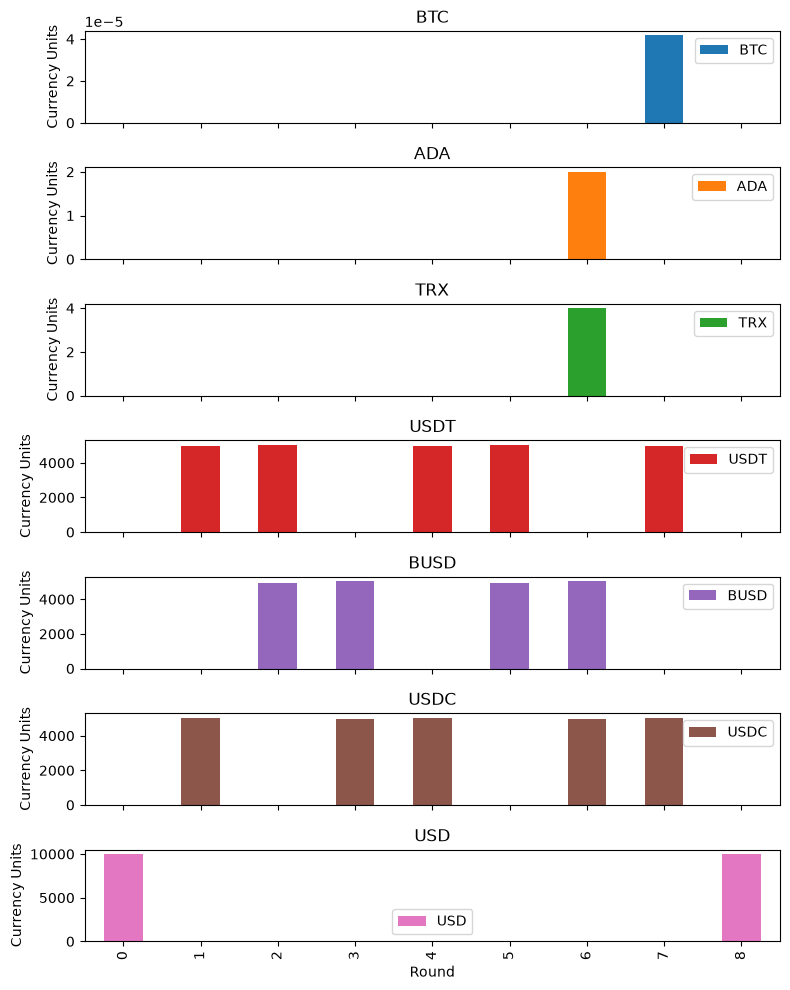

In [22]:
# display currency balances
balances = pd.DataFrame()
for node in order_book_dg.nodes:
    if sum(m.v[node, t]() for t in m.T0) > 0.0000002:
        for t in m.T0:
            balances.loc[t, node] = m.v[node, t]()

balances.plot(
    kind="bar",
    subplots=True,
    figsize=(8, 10),
    xlabel="Round",
    ylabel="Currency Units",
)
plt.gcf().tight_layout()
plt.show()

## Exercises for the reader

The previous notebook cells made certain assumptions that we need to consider. The first assumption was that there was at most one bid and one ask order between any pair of currencies in an exchange. This assumption was based on the number of orders we downloaded from the online database, but in reality, there may be more orders. How would the presence of multiple orders per pair affect our graph formulation? How can we adjust the LO formulation to account for this?

Another assumption was that we only traded currencies within one exchange. However, in reality, we can trade across multiple exchanges. How can we modify the graph-based problem formulation to accommodate this scenario?

Further, we have assigned no cost to the number of trades required to implement the strategy produced by optimization. How can the model be modified to either minimize the number of trades, or to explicitly include trading costs?

Finally, a tool like this needs to operate in real time. How can this model be incorporated into, say, a [streamlit](https://streamlit.io/) application that could be used to monitor for arbitrage opportunities in real time?

## Real Time Downloads of Order Books from an Exchange

The goal of this notebook was to show how network algorithms and optimization can be utilized to detect arbitrage opportunities within an order book that has been obtained from a cryptocurrency exchange.

The subsequent cell in the notebook utilizes `ccxt.exchange.fetch_order_book` to obtain the highest bid and lowest ask orders from an exchange for market symbols that meet the criteria of having a minimum in-degree for their base currencies.

These cells read public market data only; they do not submit trades or require credentials. Live quotes and saved outputs will differ between runs. The reported gain is a hypothetical gross return: it omits fees, assumes the displayed orders remain available, and combines quotes fetched at different times.

This exploration is switched off by default. The saved example above runs without access to an exchange API.

In [23]:
def get_order_book(exchange, exchange_dg):
    def get_orders(base, quote, limit=1):
        result = exchange.fetch_order_book("/".join([base, quote]), limit)
        if not result["asks"] or not result["bids"]:
            result = None
        else:
            result["base"], result["quote"] = base, quote
            result["timestamp"] = exchange.milliseconds()
            result["bid_price"], result["bid_volume"] = result["bids"][0][:2]
            result["ask_price"], result["ask_volume"] = result["asks"][0][:2]
        return result

    # fetch order book data and store in a dictionary
    order_book = filter(
        lambda r: r is not None,
        [get_orders(base, quote) for quote, base in exchange_dg.edges()],
    )

    # convert to pandas dataframe
    order_book = pd.DataFrame(order_book)
    if order_book.empty:
        raise ValueError("The selected markets returned no two-sided order books. Try another market selection or the saved example.")
    order_book["timestamp"] = pd.to_datetime(order_book["timestamp"], unit="ms")

    return order_book[
        [
            "symbol",
            "timestamp",
            "base",
            "quote",
            "bid_price",
            "bid_volume",
            "ask_price",
            "ask_volume",
        ]
    ]


if RUN_LIVE:
    try:
        minimum_in_degree = 10

        # get graph of market symbols with minimum_in_degree for base currencies
        exchange_dg = get_exchange_dg(exchange, minimum_in_degree)

        # get order book for all markets in the graph
        order_book = get_order_book(exchange, exchange_dg)
        order_book_dg = order_book_to_dg(order_book)

        # find trades
        v0 = 10000.0
        m = solve_crypto_model(order_book_dg, T=12, v0=v0)
        vT = m.wealth()

        print(f"Potential Return = {10000*(vT - v0)/v0:0.3f} basis points")
        display(order_book)
    except ccxt.BaseError as error:
        print(f"Live exploration unavailable: {error}")
else:
    print("Live exploration skipped; set RUN_LIVE = True to enable it.")


Live exploration skipped; set RUN_LIVE = True to enable it.


The following cell can be used to download additional order book data sets for testing. The time limit controls when a new snapshot is started; a snapshot already being downloaded can finish later. Individual requests have a ten-second timeout.

In [24]:
from datetime import datetime
import time

# get graph of market symbols with minimum_in_degree for base currencies
if RUN_LIVE:
    try:
        minimum_in_degree = 5
        exchange_dg = get_exchange_dg(exchange, minimum_in_degree)

        # search time
        search_time = 20
        timeout = time.time() + search_time

        # threshold in basis points
        arb_threshold = 1.0

        # wait for arbitrage opportunity
        print(f"Search for {search_time} seconds.")
        while time.time() <= timeout:
            print("Basis points = ", end="")
            order_book = get_order_book(exchange, exchange_dg)
            order_book_dg = order_book_to_dg(order_book)

            v0 = 10000.0
            m = solve_crypto_model(order_book_dg, T=12, v0=v0)
            vT = m.wealth()
            bp = 10000 * (vT - v0) / v0
            print(f"{bp:0.3f}")

            if bp >= arb_threshold:
                print("Positive gross return in this snapshot (before fees).")
                fname = f"{exchange} orderbook {datetime.utcnow().strftime('%Y%m%d_%H%M%S')}.csv".replace(
                    " ", "_"
                )
                order_book.to_csv(fname)
                print(f"order book saved to: {fname}")

        print("Search complete.")
    except ccxt.BaseError as error:
        print(f"Live exploration unavailable: {error}")
else:
    print("Live exploration skipped; set RUN_LIVE = True to enable it.")


Live exploration skipped; set RUN_LIVE = True to enable it.


## Bibliographic Notes

Cryptocurrency markets are relatively new compared to other markets, and relatively few academic papers are available that specifically address arbitrage on those markets. Early studies, such as the following, reported periods of large, recurrent arbitrage opportunities that exist across exchanges, and that can persist for several days or weeks.

> Makarov, I., & Schoar, A. (2020). Trading and arbitrage in cryptocurrency markets. Journal of Financial Economics, 135(2), 293-319.

Subsequent work reports these price differentials do exist, but only at a fraction of the values previously reported, and only for fleeting periods of time. 

> Crépellière, T., & Zeisberger, S. (2020). Arbitrage in the Market for Cryptocurrencies. Available at SSRN 3606053.  https://papers.ssrn.com/sol3/papers.cfm?abstract_id=3606053

The use of network algorithms to identify cross-exchange arbitrage has appeared in the academic literature, and in numerous web sites demonstrating optimization and network applications. Representative examples are cited below.

> Peduzzi, G., James, J., & Xu, J. (2021, September). JACK THE RIPPLER: Arbitrage on the Decentralized Exchange of the XRP Ledger. In 2021 3rd Conference on Blockchain Research & Applications for Innovative Networks and Services (BRAINS) (pp. 1-2). IEEE. https://arxiv.org/pdf/2106.16158.pdf

> Bruzgė, R., & Šapkauskienė, A. (2022). Network analysis on Bitcoin arbitrage opportunities. The North American Journal of Economics and Finance, 59, 101562. https://doi.org/10.1016/j.najef.2021.101562

> Bruzgė, R., & Šapkauskienė, A. (2022). Dataset for Bitcoin arbitrage in different cryptocurrency exchanges. Data in Brief, 40, 107731. 

The work in this notebook is related to materials found in the following web resources.

> https://anilpai.medium.com/currency-arbitrage-using-bellman-ford-algorithm-8938dcea56ea

> [Crypto Trading and Arbitrage Identification Strategies](https://nbviewer.org/github/rcroessmann/sharing_public/blob/master/arbitrage_identification.ipynb)

A more complete analysis of trading and exploiting arbitrage opportunities in decentralized finance markets is available in the following paper and thesis.

> Byrne, S. An Exploration of Novel Trading and Arbitrage Methods within Decentralised Finance. https://www.scss.tcd.ie/Donal.OMahony/bfg/202021/StephenByrneDissertation.pdf

> Levus, R., Berko, A., Chyrun, L., Panasyuk, V., & Hrubel, M. (2021). Intelligent System for Arbitrage Situations Searching in the Cryptocurrency Market. In CEUR Workshop Proceedings (pp. 407-440). http://ceur-ws.org/Vol-2917/paper32.pdf

In addition to the analysis of arbitrage opportunities, convex optimization may also have an important role in the development of trading algorithms for cryptocurrency exchanges.

> Angeris, G., Agrawal, A., Evans, A., Chitra, T., & Boyd, S. (2021). Constant function market makers: Multi-asset trades via convex optimization. arXiv preprint arXiv:2107.12484. https://baincapitalcrypto.com/constant-function-market-makers-multi-asset-trades-via-convex-optimization/ and https://arxiv.org/pdf/2107.12484.pdf